In [73]:
import numpy as np
from scipy.optimize import brentq
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from scipy.optimize import root
import traceback
import matplotlib.pyplot as plt

### Build Mesh

In [74]:
def solve_omega_R(R, I_contact, O_contact, L):
    """Root-finding from: 1 = R + (R/(2*I_contact)) * sum_{e=1}^{2*O_contact} omega^e
    HOW DO WE KNOW THERE IS ONE ROOT?

    Args:
        R (float): contact radius, in (0, 1).
        I_contact (int): number of elements inside the contact radius.
        O_contact (int): number of elements outside the contact radius (= E - I_contact).

    Returns:
        float or None: omega, or None if O_contact == 0 (no outer region, nothing to solve).
    """
    if O_contact == 0:
        return None
    def f(omega):
        s = sum(omega ** e for e in range(1, 2 * O_contact + 1))
        return R + (R / (2 * I_contact)) * s - L
    f1 = f(1.0)
    if f1 == 0.0:
        # ig this is for debugging
        return 1.0
    if f1 < 0.0:
        lo, hi = 1.0, 2.0
        while f(hi) < 0:
            hi *= 2
            if hi > 1e6:
                raise RuntimeError("could not bracket omega (>1 side)")
    else:
        lo, hi = 1e-8, 1.0
        while f(lo) > 0:
            lo /= 2
            if lo < 1e-12:
                raise RuntimeError("could not bracket omega (<1 side) -- R may be infeasible for this I_contact")
    return brentq(f, lo, hi)

In [75]:
def mesh_from_R(R, I_contact, E, L, non_contact_X=None):
    """Build the full 1-indexed-node mesh array X (length N = 2E+1) from the
    contact radius R alone. Inner nodes (elements 1..I_contact) are evenly spaced across [0, R];
    outer nodes (elements I_contact+1..E) are spaced geometrically by omega(R) out to r=1.

    Args:
        R (float): contact radius, in (0, 1).
        I_contact (int): number of elements inside the contact radius (fixed discretization choice).
        E (int): total number of elements.

    Returns:
        (np.ndarray, float or None): (X, omega) -- X has shape (N,) with X[0] = 0, X[-1] = 1;
        omega is None when O_contact = E - I_contact == 0.
    """
    O_contact = E - I_contact
    N = 2 * E + 1
    # spine locations
    X = np.zeros(N)
        
    if R < 1e-12:
        # taking non-contact-mesh as input avoids having to calculate it at all times
        return non_contact_X, None, False
    
    # evenly spaced spines inside the contact area
    X[0:2 * I_contact + 1] = np.linspace(0.0, R, 2 * I_contact + 1)
    # calculate increase ratio
    omega = solve_omega_R(R, I_contact, O_contact, L)
    if O_contact > 0:
        spine_loc = R
        step_base = R / (2 * I_contact)
        for e in range(1, 2 * O_contact + 1):
            spine_loc += step_base * omega ** e
            X[2 * I_contact + e] = spine_loc
    return X, omega, True

### Basis Functinos

In [76]:
def nodes_from_E(e):
    return [2 * e, 2 * e + 1, 2 * e + 2]

def values_at_E(e, value_vec):
    E1, E2, E3 = nodes_from_E(e)
    return (value_vec[E1], value_vec[E2], value_vec[E3])

In [77]:
def phi_min_1(xi):
    return 0.5 * xi * (xi - 1)

def phi_0(xi):
    return -(xi ** 2) + 1

def phi_plus_1(xi):
    return 0.5 * xi * (xi + 1)

def dphi_min_1(xi):
    return xi - 0.5

def dphi_0(xi):
    return - 2 * xi

def dphi_plus_1(xi):
    return xi + 0.5

PHI = [phi_min_1, phi_0, phi_plus_1]
DPHI = [dphi_min_1, dphi_0, dphi_plus_1]

def drdxi(xi, Xe):
    X1, X2, X3 = Xe
    return X1 * DPHI[0](xi) + X2 * DPHI[1](xi) + X3 * DPHI[2](xi)

def r_of_E(xi, Xe):
    X1, X2, X3 = Xe
    return X1 * PHI[0](xi) + X2 * PHI[1](xi) + X3 * PHI[2](xi)

### Integrals

In [78]:
# initialize integration for gaussian quadrature
XI_G, W_G = np.polynomial.legendre.leggauss(5)   # should be accurate enough for I_xixi

def gauss(f):
    return np.dot(W_G, f(XI_G))   

In [79]:
def Int_I_j(Xe_kp1, i, j):
    
    f = lambda xi: PHI[i](xi) * PHI[j](xi) * drdxi(xi, Xe_kp1)
    return gauss(f)

def Int_I_xi(Xe_kp1, Xe_k, del_t, i, j):
    
    def vel_sum(xi):
        return sum((((Xe_kp1[m] - Xe_k[m])/del_t) * PHI[m](xi))for m in range(3))
    
    f = lambda xi: vel_sum(xi) * PHI[i](xi) * DPHI[j](xi)
    return gauss(f)

def Int_I_xixi(Xe_kp1, i, j):
    
    f = lambda xi: DPHI[j](xi) * (DPHI[i](xi) * 1/drdxi(xi, Xe_kp1) - PHI[i](xi)/(r_of_E(xi, Xe_kp1)))
    return gauss(f)

def Int_I(Xe_kp1, i):
    
    f = lambda xi: PHI[i](xi) * drdxi(xi, Xe_kp1)
    return gauss(f)

### Building Vec

In [80]:
def residuals(alpha_k, alpha_kp1, beta_k, beta_kp1, gamma_kp1, X_kp1, X_k, del_t, E, I, Fr):
    
    res_eta_vec = np.zeros(2 * E + 1)
    res_u_vec = np.zeros(2 * E + 1)
    
    for ele in range(E):
        
        Xe_k = values_at_E(ele, X_k)
        Xe_kp1 = values_at_E(ele, X_kp1)
                                
        alpha_k_e = values_at_E(ele, alpha_k)
        alpha_kp1_e = values_at_E(ele, alpha_kp1)
                                
        beta_k_e = values_at_E(ele, beta_k)
        beta_kp1_e = values_at_E(ele, beta_kp1)
                                
        gamma_kp1_e = values_at_E(ele, gamma_kp1)
        
        ele_nodes = nodes_from_E(ele)
        
        
        for local_i in range(3):
            
            for j in range(3):
                I_j = Int_I_j(Xe_kp1, local_i, j)
                I_xi = Int_I_xi(Xe_kp1, Xe_k, del_t, local_i, j)
                        
                res_eta_vec[ele_nodes[local_i]] += ((alpha_kp1_e[j] - alpha_k_e[j] - del_t * beta_kp1_e[j]) * I_j 
                                                    - del_t * (alpha_kp1_e[j] * I_xi )) 
                    
                res_u_vec[ele_nodes[local_i]] += ((beta_kp1_e[j] - beta_k_e[j] + del_t * gamma_kp1_e[j]) * I_j 
                                                    - del_t * beta_kp1_e[j] * I_xi)
                
                # additional outside the pressed area
                if ele >= I:
                    I_xixi = Int_I_xixi(Xe_kp1, local_i, j)
                    res_u_vec[ele_nodes[local_i]] += del_t * alpha_kp1_e[j] * I_xixi
                    
                    # adding DR term for phi = 2I+1 (1-indexing)
                    if ele == I:
                        if local_i == 0:
                            res_u_vec[ele_nodes[local_i]] += del_t * PHI[local_i](-1) * alpha_kp1_e[j] * DPHI[j](-1) * 1 / drdxi(-1, Xe_kp1)
                            
            # additional inside the pressed area                    
            if ele < I:
                res_u_vec[ele_nodes[local_i]] -= (2 * del_t) * Int_I(Xe_kp1, local_i)
                
                
            res_u_vec[ele_nodes[local_i]] += del_t * Int_I(Xe_kp1, local_i) * Fr
            
                
    # changing last equation for alpha
    res_eta_vec[-1] = alpha_kp1[-1]
                        
    # adding boundary term & co to last 
    res_u_vec[-1] = beta_kp1[-1]
            
    return res_eta_vec, res_u_vec

In [81]:
def liftoff_residuals(alpha_k, alpha_kp1, beta_k, beta_kp1, gamma_kp1, X_kp1, X_k, del_t, E, I, Fr):
    
    res_eta_vec = np.zeros(2 * E + 1)
    res_u_vec = np.zeros(2 * E + 1)
    
    for ele in range(E):
        
        Xe_k = values_at_E(ele, X_k)
        Xe_kp1 = values_at_E(ele, X_kp1)
                                
        alpha_k_e = values_at_E(ele, alpha_k)
        alpha_kp1_e = values_at_E(ele, alpha_kp1)
                                
        beta_k_e = values_at_E(ele, beta_k)
        beta_kp1_e = values_at_E(ele, beta_kp1)
                                
        gamma_kp1_e = values_at_E(ele, gamma_kp1)
        
        ele_nodes = nodes_from_E(ele)
        
        
        for local_i in range(3):
            
            for j in range(3):
                I_j = Int_I_j(Xe_kp1, local_i, j)
                I_xi = Int_I_xi(Xe_kp1, Xe_k, del_t, local_i, j)
                I_xixi = Int_I_xixi(Xe_kp1, local_i, j)
                        
                res_eta_vec[ele_nodes[local_i]] += ((alpha_kp1_e[j] - alpha_k_e[j] - del_t * beta_kp1_e[j]) * I_j 
                                                    - del_t * (alpha_kp1_e[j] * I_xi )) 
                    
                res_u_vec[ele_nodes[local_i]] += ((beta_kp1_e[j] - beta_k_e[j] + del_t * gamma_kp1_e[j]) * I_j 
                                                    - del_t * beta_kp1_e[j] * I_xi + del_t * alpha_kp1_e[j] * I_xixi)              
                
            res_u_vec[ele_nodes[local_i]] += del_t * Int_I(Xe_kp1, local_i) * Fr
            
                
    # changing last equation for alpha
    res_eta_vec[-1] = alpha_kp1[-1]
                        
    # adding boundary term & co to last 
    res_u_vec[-1] = beta_kp1[-1]
            
    return res_eta_vec, res_u_vec

In [82]:
def v_vec(gamma_kp1, v_k, v_kp1, X_kp1, del_t, I, Fr, m):
    
    pressure_cont = 0 
    
    for ele in range(I):
        Xe_kp1 = values_at_E(ele, X_kp1)
        gamma_e = values_at_E(ele, gamma_kp1)
        
        for j in range(3):
            f = lambda xi: PHI[j](xi) * r_of_E(xi, Xe_kp1) * drdxi(xi, Xe_kp1)
            pressure_cont += gamma_e[j] * gauss(f)
            
    return v_kp1 - v_k + del_t * (Fr - 2 * (np.pi/m) * pressure_cont)

In [83]:
def build_vec(alpha_k, alpha_kp1, beta_k, beta_kp1, gamma_kp1, 
                h_k, h_kp1, v_k, v_kp1, X_kp1, X_k, 
                del_t, E, I, Fr, m, R_start):
    
    R_kp1 = X_kp1[2*I]
    
    res = residuals(alpha_k, alpha_kp1, beta_k, beta_kp1, gamma_kp1, X_kp1, X_k, del_t, E, I, Fr)
    
    pres_outside_contact = gamma_kp1[2*I+1:]
    
    contact_cond = np.zeros(2 * I + 1)
    for j in range(2 * I + 1):
        contact_cond[j] = h_kp1 - np.cos(np.arcsin((j * R_kp1)/(2 * I))) - alpha_kp1[j]
        
    # getting values for first non-contact element
    alpha_kp1_e = values_at_E(I, alpha_kp1)
    X_kp1_e = values_at_E(I, X_kp1)
    tangent_cond = np.array([np.tan(np.arcsin(R_kp1)) - 1/(drdxi(-1, X_kp1_e)) * sum((alpha_kp1_e[j] * DPHI[j](-1)) for j in range(3))])
    
    vertical_vel_vec = np.zeros((2))
    vertical_vel_vec[0] = h_kp1 - h_k - del_t * v_kp1            
    vertical_vel_vec[1] = v_vec(gamma_kp1, v_k, v_kp1, X_kp1, del_t, I, Fr, m)
    
    return np.concatenate([*res, pres_outside_contact, contact_cond, tangent_cond, vertical_vel_vec])

In [84]:
def build_liftoff_vec(alpha_k, alpha_kp1, beta_k, beta_kp1, gamma_kp1, 
                h_k, h_kp1, v_k, v_kp1, X_kp1, X_k, 
                del_t, E, I, Fr, m, R_start):
        
        res = liftoff_residuals(alpha_k, alpha_kp1, beta_k, beta_kp1, gamma_kp1, X_kp1, X_k, del_t, E, I, Fr)
        
        # no contact
        pres_outside_contact = gamma_kp1
        # set radius equal to 0 instead of enforcing tangent condition
        # keep the mesh radius constant
        tangent_cond = np.array([R_start - X_kp1[2*I]])
        
        vertical_vel_vec = np.zeros((2))
        vertical_vel_vec[0] = h_kp1 - h_k - del_t * v_kp1            
        vertical_vel_vec[1] = v_kp1 - v_k + del_t * Fr
        
        return np.concatenate([*res, pres_outside_contact, tangent_cond, vertical_vel_vec])

### Building Jacobian

In [85]:
def dresidual(X_k, X_kp1, del_t, E, I):
    N = 2*E + 1
    dReta_dalpha = np.zeros((N, N))
    dReta_dbeta = np.zeros((N, N))        
    dReta_dgamma = np.zeros((N, N))
        
        
    dRu_dalpha = np.zeros((N, N))
    dRu_dbeta = np.zeros((N, N))
    dRu_dgamma = np.zeros((N, N))
        
    for ele in range(E):
        Xe_k = values_at_E(ele, X_k)
        Xe_kp1 = values_at_E(ele, X_kp1)
        nodes_ele = nodes_from_E(ele)
            
        for i in range(3):
            for j in range(3):
                I_j = Int_I_j(Xe_kp1, i, j)
                I_xi = Int_I_xi(Xe_kp1, Xe_k, del_t, i, j)
                    
                dReta_dalpha[nodes_ele[i], nodes_ele[j]] += I_j - del_t * I_xi
                dReta_dbeta[nodes_ele[i], nodes_ele[j]] += I_j
                
                
                dRu_dbeta[nodes_ele[i], nodes_ele[j]]  += I_j - del_t * I_xi
                dRu_dgamma[nodes_ele[i], nodes_ele[j]] += I_j
                                    
                    
                if ele >= I:
                    I_xixi = Int_I_xixi(Xe_kp1, i, j)
                    dRu_dalpha[nodes_ele[i], nodes_ele[j]] += del_t * I_xixi 
                
                # adding derivative of Dr; right side
                if ele == I and i == 0:
                    dRu_dalpha[nodes_ele[i], nodes_ele[j]] += del_t * DPHI[j](-1) * 1/drdxi(-1, Xe_kp1)
                    
    dReta_dbeta *= -del_t
    dRu_dgamma *= del_t    
    
    # since last residual in eta is simple alpha_N, need to adjust derivatives
    dReta_dalpha[-1], dReta_dbeta[-1] = 0, 0
    dReta_dalpha[-1, -1] = 1
    
    # last residual in u contains an extra term
    dRu_dalpha[-1], dRu_dbeta[-1] = 0, 0
    dRu_dbeta[-1, -1] = 1
    
    return dReta_dalpha, dReta_dbeta, dReta_dgamma, dRu_dalpha, dRu_dbeta, dRu_dgamma

In [86]:
def dresidual_liftoff(X_k, X_kp1, del_t, E, I):
    N = 2*E + 1
    dReta_dalpha = np.zeros((N, N))
    dReta_dbeta = np.zeros((N, N))        
    dReta_dgamma = np.zeros((N, N))
        
        
    dRu_dalpha = np.zeros((N, N))
    dRu_dbeta = np.zeros((N, N))
    dRu_dgamma = np.zeros((N, N))
        
    for ele in range(E):
        Xe_k = values_at_E(ele, X_k)
        Xe_kp1 = values_at_E(ele, X_kp1)
        nodes_ele = nodes_from_E(ele)
            
        for i in range(3):
            for j in range(3):
                I_j = Int_I_j(Xe_kp1, i, j)
                I_xi = Int_I_xi(Xe_kp1, Xe_k, del_t, i, j)
                    
                dReta_dalpha[nodes_ele[i], nodes_ele[j]] += I_j - del_t * I_xi
                dReta_dbeta[nodes_ele[i], nodes_ele[j]] += I_j
                
                
                dRu_dbeta[nodes_ele[i], nodes_ele[j]]  += I_j - del_t * I_xi
                dRu_dgamma[nodes_ele[i], nodes_ele[j]] += I_j
                                    
                
                I_xixi = Int_I_xixi(Xe_kp1, i, j)
                dRu_dalpha[nodes_ele[i], nodes_ele[j]] += del_t * I_xixi 
                    
    dReta_dbeta *= -del_t
    dRu_dgamma *= del_t    
    
    # since last residual in eta is simple alpha_N, need to adjust derivatives
    dReta_dalpha[-1], dReta_dbeta[-1] = 0, 0
    dReta_dalpha[-1, -1] = 1
    
    # last residual in u contains an extra term
    dRu_dalpha[-1], dRu_dbeta[-1] = 0, 0
    dRu_dbeta[-1, -1] = 1
    
    return dReta_dalpha, dReta_dbeta, dReta_dgamma, dRu_dalpha, dRu_dbeta, dRu_dgamma

In [87]:
def dresidual_R(alpha_k, alpha_kp1, beta_k, beta_kp1, gamma_kp1, X_k, X_kp1, del_t, I, E, Fr, L, non_contact_X, eps=1e-6):
    
    R_kp1 = X_kp1[2*I]
    
    def resid(R):
        X_kp1, _, _ = mesh_from_R(R, I, E, L, non_contact_X)
        eta_R, u_R = residuals(alpha_k, alpha_kp1, beta_k, beta_kp1, gamma_kp1, X_kp1, X_k, del_t, E, I, Fr)
        return eta_R, u_R
        
    R_plus = R_kp1 + eps
    eta_R_plus, u_R_plus = resid(R_plus)
    
    R_minus = R_kp1 - eps
    eta_R_minus, u_R_minus = resid(R_minus)
    
    return (eta_R_plus - eta_R_minus)/(2*eps), (u_R_plus - u_R_minus)/(2*eps)

In [88]:
def dresidual_R_liftoff(alpha_k, alpha_kp1, beta_k, beta_kp1, gamma_kp1, X_k, X_kp1, del_t, I, E, Fr, L, non_contact_X, eps=1e-6):
    
    R_kp1 = X_kp1[2*I]
    
    def resid(R):
        X_kp1, _, _ = mesh_from_R(R, I, E, L, non_contact_X)
        eta_R, u_R = liftoff_residuals(alpha_k, alpha_kp1, beta_k, beta_kp1, gamma_kp1, X_kp1, X_k, del_t, E, I, Fr)
        return eta_R, u_R
        
    R_plus = R_kp1 + eps
    eta_R_plus, u_R_plus = resid(R_plus)
    
    R_minus = R_kp1 - eps
    eta_R_minus, u_R_minus = resid(R_minus)
    
    return (eta_R_plus - eta_R_minus)/(2*eps), (u_R_plus - u_R_minus)/(2*eps)

In [89]:
def dcontact(R_kp1, I, E):
    
    O = E - I
    N = 2 * E + 1
    
    dcontact_dalpha = np.hstack((-1*np.eye(2*I+1), np.zeros((2*I+1, 2*O))))
    dcontact_dR = np.zeros((2*I+1, 1))
    
    for i in range(2*I+1):
        numerator =  (i)**2 * R_kp1
        denominator = 4 * (I)**2 * np.sqrt(1 - ((i* R_kp1) **2/(4 * (I)**2)))
        
        dcontact_dR[i] = numerator / denominator
    
    return np.hstack((dcontact_dalpha, np.zeros((2*I+1, 2*N)), np.ones((2*I+1, 1)), np.zeros((2*I+1, 1)), dcontact_dR))

In [90]:
def dtangent(X_kp1, alpha_kp1, I, E, L, non_contact_X, eps = 1e-6):
    
    Xe_kp1 = values_at_E(I, X_kp1) 
    R_kp1 = X_kp1[2*I]
    O = E - I
    N = 2 * E + 1
    
    alpha_kp1_e = values_at_E(I, alpha_kp1)
    dxidr = 1/(drdxi(-1, Xe_kp1))
    
    
    # derivative with respect to alpha
    center = np.array([[-DPHI[j](-1.0) * dxidr for j in range(3)]])
    dtangent_dalpha = np.hstack(((np.zeros((1, 2*I)), center, np.zeros((1, 2*O-2)))))


    # calculating deta/dr from outside (mesh-dependent)
    def deta_dr_outer(X_R):
        Xe = values_at_E(I, X_R)
        return sum(alpha_kp1_e[j] * DPHI[j](-1.0) for j in range(3)) / drdxi(-1.0, Xe)

    def f(R):
        X_R, _, _ = mesh_from_R(R, I, E, L, non_contact_X)
        return np.tan(np.arcsin(R)) - deta_dr_outer(X_R)

    dtangent_dr = (f(R_kp1 + eps) - f(R_kp1 - eps)) / (2 * eps)
    
    return np.hstack((dtangent_dalpha, np.zeros((1, 2 * N + 2)), [[dtangent_dr]]))

In [91]:
def dvel(gamma_kp1, X_kp1, del_t, E, I, Fr, m, non_contact_X, L, eps=1e-6):
    
    N = 2 * E + 1
    R_kp1 = X_kp1[2*I]
    
    dv_gamma = np.zeros(N)
    
    for ele in range(I):
        Xe_kp1 =  values_at_E(ele, X_kp1)
        nodes_e = nodes_from_E(ele)
        
        for j in range(3):
            f = lambda xi: PHI[j](xi) * r_of_E(xi, Xe_kp1) *  drdxi(xi, Xe_kp1)
            dv_gamma[nodes_e[j]] += gauss(f)
            
    dv_gamma *= -del_t * (2 * np.pi / m)
    

    def v(R):
        X_kp1, _, _ = mesh_from_R(R, I, E, L, non_contact_X)
        v_of_R = v_vec(gamma_kp1, 0, 0, X_kp1, del_t, I, Fr, m)
        return v_of_R
    
    v_R_plus = v(R_kp1 + eps)
    v_R_min = v(R_kp1 - eps)
    dv_R = (v_R_plus - v_R_min)/(2 * eps)
    
    return np.concatenate([np.zeros(2*N), dv_gamma, [0], [1], [dv_R]])
        

In [92]:
def Jacobian(alpha_k, alpha_kp1, beta_k, beta_kp1, gamma_kp1, X_k, X_kp1, del_t, I, E, Fr, L, m, non_contact_X):
    
    O = E - I
    N = 2 * E + 1
    
    # Residual Derivatives
    dReta_dalpha, dReta_dbeta, dReta_dgamma, dRu_dalpha, dRu_dbeta, dRu_dgamma = dresidual(X_k, X_kp1, del_t, E, I)
    d_eta_r, d_u_r = dresidual_R(alpha_k, alpha_kp1, beta_k, beta_kp1, gamma_kp1, X_k, X_kp1, del_t, I, E, Fr, L, non_contact_X)
    
    dReta = np.hstack((dReta_dalpha, dReta_dbeta, dReta_dgamma, np.zeros((N, 2)), d_eta_r.reshape(-1, 1)))
    dRu = np.hstack((dRu_dalpha, dRu_dbeta, dRu_dgamma, np.zeros((N, 2)), d_u_r.reshape(-1, 1)))
    
    
    # Pressure derivatives
    dgamma = np.hstack((np.zeros((2 * O, 2 * N + 2 * I + 1)), np.eye(2*O), np.zeros((2*O, 3))))
    
    
    #contact derivatives
    R_kp1 = X_kp1[2*I]
    dcon = dcontact(R_kp1, I, E)
    
    
    # tangent derivative
    dtan = dtangent(X_kp1, alpha_kp1, I, E, L, non_contact_X)
    
    
    # vertical fall derivatives
    dh = np.hstack((np.zeros((1, 3*N)), np.array([[1, -del_t]]), np.zeros((1,1))))
    dv = dvel(gamma_kp1, X_kp1, del_t, E, I, Fr, m, non_contact_X, L)
    
    
    J = np.vstack((dReta, dRu, dgamma, dcon, dtan, dh, dv))
    
    return J

In [93]:
def liftoff_Jacobian(alpha_k, alpha_kp1, beta_k, beta_kp1, gamma_kp1, X_k, X_kp1, del_t, I, E, Fr, L, m, non_contact_X):
    
    N = 2 * E + 1
    
    # Residual Derivatives
    dReta_dalpha, dReta_dbeta, dReta_dgamma, dRu_dalpha, dRu_dbeta, dRu_dgamma = dresidual_liftoff(X_k, X_kp1, del_t, E, I)
    d_eta_r, d_u_r = dresidual_R_liftoff(alpha_k, alpha_kp1, beta_k, beta_kp1, gamma_kp1, X_k, X_kp1, del_t, I, E, Fr, L, non_contact_X)
    
    dReta = np.hstack((dReta_dalpha, dReta_dbeta, dReta_dgamma, np.zeros((N, 2)), d_eta_r.reshape(-1, 1)))
    dRu = np.hstack((dRu_dalpha, dRu_dbeta, dRu_dgamma, np.zeros((N, 2)), d_u_r.reshape(-1, 1)))
    
    
    # Pressure derivatives
    dgamma = np.hstack((np.zeros((N, 2 * N)), np.eye(N), np.zeros((N, 3))))
    
    
    # tangent derivative turns into derivative with respect to R only (bc in vec it is R)
    dtan = np.hstack((np.zeros((1, 3*N+2)), np.array([[-1]])))
    
    
    # vertical fall derivatives
    dh = np.hstack((np.zeros((1, 3*N)), np.array([[1, -del_t]]), np.zeros((1,1))))
    dv = np.hstack((np.zeros((1, 3*N + 1)), np.array([[1]]), np.zeros((1,1))))
    
    
    J = np.vstack((dReta, dRu, dgamma, dtan, dh, dv))
    
    return J

### Solver

In [94]:
def unflatten(x_vec, N):
    alpha_kp1 = x_vec[0:N]
    beta_kp1  = x_vec[N:2 * N]
    gamma_kp1 = x_vec[2 * N:3 * N]
    h_kp1 = x_vec[3 * N]
    v_kp1 = x_vec[3 * N + 1]
    R_kp1 = x_vec[-1]
    # print("unflatten: Done with unflattening")
    return alpha_kp1, beta_kp1, gamma_kp1, h_kp1, v_kp1, R_kp1

In [95]:
def all_roots(f, a, b, n=100):
    x = np.linspace(a, b, n)
    y = f(x)
    roots = []
    for k in range(n - 1):
        if y[k] == 0:
            roots.append(x[k])
        elif y[k] * y[k + 1] < 0:          # sign change between x[k] and x[k+1]
            roots.append(brentq(f, x[k], x[k + 1]))
    if y[-1] == 0:
        roots.append(x[-1])
    return roots

In [96]:
def check_penetration(alpha_kp1, h_kp1, X_kp1, E, start_ele = 0, tol=1e-12):
    """Returns (True, None) if the sphere does not penetrate the membrane,
    otherwise (False, r of the rightmost penetration minimum)."""
    
    intersect = False
    intersection_at = 0.0
    max_depth = 0.0          
    r_depth = None

    for ele in range(start_ele, E):
        Xe = values_at_E(ele, X_kp1)
        if Xe[0] >= 1:                 
            break                       
        eta1, eta2, eta3 = values_at_E(ele, alpha_kp1)

        def r_clip(xi):                 # stay inside the sphere's footprint
            return np.minimum(r_of_E(xi, Xe), (1 - 1e-12))

        def dif(xi):                    # sphere bottom - membrane; < 0 means penetration
            r = r_clip(xi)
            sphere = h_kp1 - np.cos(np.arcsin(r))
            eta = eta1*PHI[0](xi) + eta2*PHI[1](xi) + eta3*PHI[2](xi)
            return sphere - eta

        def d_dif(xi):                  # derivative of dif with respect to xi
            r = r_clip(xi)
            dsphere = r / np.sqrt(1 - r**2) * drdxi(xi, Xe)
            deta = eta1*DPHI[0](xi) + eta2*DPHI[1](xi) + eta3*DPHI[2](xi)
            return dsphere - deta

        roots = all_roots(d_dif, -1, 1)
        min_cands = np.array([-1.0, 1.0] + roots)
        min_vals  = np.array([dif(xi) for xi in min_cands])

        below = min_vals < -tol         # strictly penetrating
        if np.any(below):
            intersect = True
            k = np.argmin(min_vals)                      # deepest point in this element
            if min_vals[k] < max_depth:
                max_depth = min_vals[k]
                r_depth = r_of_E(min_cands[k], Xe)
            # rightmost penetrating point in this element
            xi_pen = np.max(min_cands[below])
            # walk right to where the gap returns to >= 0, if it does inside the element
            if dif(1.0) < 0:
                xi_edge = 1.0                               # overlap continues into the next element
            else:
                xi_edge = brentq(dif, xi_pen, 1.0)          # exact zero crossing
            intersection_at = max(intersection_at, r_of_E(xi_edge, Xe))

    
    if intersect:
        print(f"penetration: depth {-max_depth:.2e} at r = {r_depth:.4f}, overlap up to r = {intersection_at:.4f}")
        return False, intersection_at
    
    return True, None

In [97]:
def newton(F, J, x0, tol=1e-12, max_it=25):
    """Plain Newton: x <- x - J(x)^{-1} F(x).
    Returns (x, converged)."""
    x = np.array(x0, dtype=float).copy()
    
    for it in range(max_it):
        f = F(x)
        res = np.max(np.abs(f))
        try:
            dx = np.linalg.solve(J(x), -f)
        except np.linalg.LinAlgError:
            return x, False
        x = x + dx
        if not np.all(np.isfinite(x)):
            return x, False
        if res < tol:      # step tiny AND residual small
            return x, True
    return x, False

In [98]:
def solve_system(x0_vec, del_t, E, I, Fr, L, m, non_contact_X, R_start, 
                    mode='contact', accept_tol=1e-12):

    N = 2 * E + 1
    x0_flat = np.asarray(x0_vec).flatten().copy()
    alpha_k, beta_k, gamma_k, h_k, v_k, R_k = unflatten(x0_flat, N)
    X_k, _, _ = mesh_from_R(R_k, I, E, L, non_contact_X)

    # pick the system once; it stays fixed for the whole solve
    vec_fn = build_vec if mode == 'contact' else build_liftoff_vec
    jac_fn = Jacobian  if mode == 'contact' else liftoff_Jacobian

    def F_flat(xi):
        alpha_kp1, beta_kp1, gamma_kp1, h_kp1, v_kp1, R_kp1 = unflatten(xi, N)
        X_kp1, _, _ = mesh_from_R(R_kp1, I, E, L, non_contact_X)
        return vec_fn(alpha_k, alpha_kp1, beta_k, beta_kp1, gamma_kp1,
                        h_k, h_kp1, v_k, v_kp1, X_kp1, X_k,
                        del_t, E, I, Fr, m, R_start)

    def J_flat(xi):
        alpha_kp1, beta_kp1, gamma_kp1, h_kp1, v_kp1, R_kp1 = unflatten(xi, N)
        X_kp1, _, _ = mesh_from_R(R_kp1, I, E, L, non_contact_X)
        return jac_fn(alpha_k, alpha_kp1, beta_k, beta_kp1, gamma_kp1,
                        X_k, X_kp1, del_t, I, E, Fr, L, m, non_contact_X)

    try:
        sol, accepted = newton(F_flat, J_flat, x0_flat)
    except Exception as e:                       # catch everything, not just RuntimeError
        traceback.print_exc()
        print(f"solve_system ({mode}): raised {type(e).__name__}: {e}")
        return False

    if accepted:
        return sol
    
    return False

In [99]:
def try_liftoff(x, I, E, L, non_contact_X):
    N = 2 * E + 1
    
    alpha, _, _, h, _, _ = unflatten(x, N)
    X_c, _, _ = mesh_from_R(x[-1], I, E, L, non_contact_X)   
    ok, R_pen = check_penetration(alpha, h, X_c, E)
                    
    if ok:
        return True, None
    
    return False, R_pen

def try_contact(x, I, E, L, non_contact_X):
    N = 2 * E + 1
    alpha, _, _, h, _, _ = unflatten(x, N)
    X_c, _, _ = mesh_from_R(x[-1], I, E, L, non_contact_X)   
    ok, R_pen = check_penetration(alpha, h, X_c, E, start_ele=I)
                    
    if ok:
        return True, None
    
    return False, R_pen

In [100]:
def solve_step(x_k, del_t, E, I, Fr, L, m, non_contact_X, R_start, prev_mode='contact'):
    

    """Returns (x_kp1, mode) or (False, prev_mode)."""
    R_MIN = 5 * 1e-5
    del_R = 5 * 1e-3
    N = 2 * E + 1
    guess = np.asarray(x_k, dtype=float).copy()
    
    # if previous mode is contact, try contact
    if prev_mode == 'contact':
        # print("prev mode = contact")
        x = solve_system(guess, del_t, E, I, Fr, L, m, non_contact_X, R_start, mode='contact')
        
        # if solver converges
        if x is not False:
            R = x[-1]
            if R >= R_MIN:
                res, R_pen = try_contact(x, I, E, L, non_contact_X)
                if res == True:
                    #print("first contact solve works!")
                    return x, 'contact'
                
                # try contact solution with bigger R
                if R_pen > R:
                    #print("first contact solve did not work, trying with R", R_pen)
                    new_guess = guess.copy()
                    new_guess[-1] = min(R+del_R, R_pen)
                    
                    x = solve_system(new_guess, del_t, E, I, Fr, L, m, non_contact_X, R_start, mode='contact')
                            
                    # if solver converges
                    if x is not False:
                        R = x[-1]
                        if R >= R_MIN:
                            res, R_pen = try_contact(x, I, E, L, non_contact_X)
                            if res == True:
                                #print(f"second contact guess works")
                                return x, 'contact'
                #         else:
                #             #print(f"contact R = {R:.2e} too small -> trying liftoff")
                #     else:
                #         print("second contact solve did not work")
                # else:
                #     print("contact penetrates but penetration less than R?")
                
        #     else:            
        #         print(f"contact R = {R:.2e} too small -> trying liftoff")
            
        # print("contact did not converge") 
        # try liftoff if contact failed and if the change in radius would not be greater than allowed
        if guess[-1] <= del_R:
            x = solve_system(guess, del_t, E, I, Fr, L, m, non_contact_X, R_start, mode='liftoff')
            if x is not False:
                res, R_pen = try_liftoff(x, I, E, L, non_contact_X)
                
                if res == True:
                    # print("liftoff works")
                    return x, 'liftoff'
                
                # print("liftoff converged but penetrates")
                # print("Trying with R", max(R_pen, R_MIN))
                new_guess = guess.copy()
                new_guess[-1] = max(R_pen, R_MIN)
                                    
                x = solve_system(new_guess, del_t, E, I, Fr, L, m, non_contact_X, R_start, mode='contact')
                                            
                # if solver converges
                if x is not False:
                    R = x[-1]
                    if R >= R_MIN:
                        res, R_pen = try_contact(x, I, E, L, non_contact_X)
                        if res == True:
                            # print(f"second contact guess works")
                            return x, 'contact'
        #                 else:
        #                     print(f"contact R = {R:.2e} too small -> trying liftoff")
        #             else:
        #                 print("second contact solve did not work")
                
                
        #     else:
        #         print("liftoff did not converge")
        # else:
        #     print("previous radius too big to try liftoff: ", guess[-1])
                        
        return False, 'contact'
    
    # print("previous mode is liftoff")
    # else if previous mode is liftoff, try liftoff first
    x = solve_system(guess, del_t, E, I, Fr, L, m, non_contact_X, R_start, mode='liftoff')
    # if liftoff converges, check penetration
    
    if x is not False:
        res, R_pen = try_liftoff(x, I, E, L, non_contact_X)
                    
        if res == True:
            # print("liftoff works")
            return x, 'liftoff'
        
        # print("liftoff penetrates")
        
        # if liftoff penetrates, we try contact with adapted guess
        if R_pen < R_MIN:
            R_pen = R_MIN
                        
        # if liftoff does 
        if R_pen < guess[-1]:
            R_guess = max(R_pen, guess[-1]-del_R)
        else:
            R_guess = min(R_pen, guess[-1]+del_R)
                        
        new_guess = guess.copy()
        new_guess[-1] = R_guess
        x = solve_system(new_guess, del_t, E, I, Fr, L, m, non_contact_X, R_start, mode='contact')
        # if contact converges 
        if x is not False:
            R = x[-1]
            if R >= R_MIN:
                res, R_pen = try_contact(x, I, E, L, non_contact_X)
                if res == True:
                    # print("contact works")
                    return x, 'contact'
    
    # if liftoff does not converge, try contact
    else:
        # print("liftoff does not converge, trying contact")
        x = solve_system(guess, del_t, E, I, Fr, L, m, non_contact_X, R_start, mode='contact')
                
        # if solver converges
        if x is not False:
            R = x[-1]
            if R >= R_MIN:
                res, R_pen = try_contact(x, I, E, L, non_contact_X)
                if res == True:
                    # print("contact works")
                    return x, 'contact'
        # print("contact does not work")
    
    return False, 'liftoff'

### Running Simulation

In [101]:
def run_simulation(Fr, V0, m_bar, L, E=50, I=30, dt=0.005, T_end=100, lift_off_end = True):
    
    N = 2 * E + 1

    # time variables
    t_list = np.arange(0, T_end, dt)
    t_idx = 0
    del_R = 5 * 1e-3

    mode = 'contact'
    

    # initial area guess
    def initial_guess(dt, v_bar=V0):
        h_freefall = 1 - dt * v_bar
        intersec_angle = np.arccos(h_freefall)
        horizontal_intersec = np.sin(intersec_angle)
        R0 = horizontal_intersec/2
        return R0

    # initial conditions
    R0 = initial_guess(dt)
    non_contact_X = np.zeros(N)
    print(1, -V0, R0, del_R)
    X0, _ , _= mesh_from_R(R0, I, E, L, non_contact_X)
    # set non contact mesh t obe initial mesh
    
    def initial_eta(Fr, X0, L):
        R = 2/np.abs(Fr)
        eta_0 = []
        def eta_of_r(r):
            if R < L:
                print("Curvature is inaccurate")
                return None
            return np.sqrt(R**2 - L**2) - np.sqrt(R**2 - r**2)
        for x in X0:
            eta_0.append(eta_of_r(x))
        
        return np.array(eta_0)
    
    eta_0 = initial_eta(Fr, X0, L)
    h0 = 1 + eta_0[0]
    x0_vec = np.concatenate([eta_0, np.zeros(2*N), [h0, -V0, R0]])
    
    # mesh for free fall
    non_contact_X = X0.copy()

    # initialize storing arrays
    all_xs = [x0_vec]
    all_ts = [0.0]
    all_modes = ['contact']
    
    R_min = del_R
    
    print(f"Running: E={E} N={N} I={I} dt0={dt} T_end={T_end}")

    while t_idx < (len(t_list) - 1):
        
        x_k = all_xs[-1]
        dt = t_list[t_idx + 1] - t_list[t_idx]
        
        print("⏰ Index: ", t_idx, "Time: ", all_ts[t_idx], "delta t", dt, "R: ", all_xs[-1][-1], "h: ", all_xs[-1][-3])
        
        # break in case time step gets too small
        if dt < 1e-12:
            print("Too small time step")
            break
        
        if t_idx == 0:
            x_k[-1] = initial_guess(dt)
        
        if (t_idx > 10) and (lift_off_end == True):
            if all_xs[-1][-3] > h0:
                break
            
        result, curr_mode = solve_step(x_k, dt, E, I, Fr, L, m_bar, non_contact_X, R0, prev_mode = mode)
        
        # if solver does not converge, half time step
        if result is False:
            t_insert = (t_list[t_idx + 1] + t_list[t_idx]) / 2
            t_list = np.insert(t_list, t_idx + 1, t_insert)
            print("Halving dt")
            
        else:
            # check that radius does not grow or shrink too much at once
            if (np.abs(result[-1] - all_xs[-1][-1]) < R_min) or (t_idx == 0) or (mode=='contact' and curr_mode=='liftoff'):
                all_xs.append(result)
                all_ts.append(t_list[t_idx + 1])
                mode = curr_mode
                all_modes.append(mode)
                t_idx += 1
            else:
                t_insert = (t_list[t_idx + 1] + t_list[t_idx]) / 2
                t_list = np.insert(t_list, t_idx + 1, t_insert)
                print("too big change in contact radius: ", (np.abs(result[-1] - all_xs[-1][-1])),  "Halving dt : ")

    print(f"Done. {len(all_xs)} accepted states.")
    
    return all_xs, all_ts, all_modes

In [102]:
def M_sphere(rho_s, R_s):
    return (4/3) * np.pi * R_s**3 * rho_s

def froude(Rs, rho, tau, g = 9.81):
    return Rs * rho * g / tau

def V_0(V, rho, tau):
    return V / np.sqrt(tau/rho)

def mathcal_L(Rs, L):
    return L/Rs

def m_bar(M, rho, Rs):
    return M/(rho * Rs**2)

In [103]:
# EVLIS PARAMETERS

V0 = np.linspace(0.25, 1.0, 10)
length = 0.0525 # m
Rs = 0.00238 # m
rho = 0.3 # kg / m^2
tau = 107 # N / m
rho_s_1 = 3250 # kg/ m^3 (3.25 g / cm^3)
rho_s_2 = 7930 # kg/ m^3 (7.93 g / cm^3)

Froude = froude(Rs, rho, tau)
V0s = V_0(V0, rho, tau)
L = mathcal_L(Rs, length)

m1 = m_bar(M_sphere(rho_s_1, Rs), rho, Rs)
m2 = m_bar(M_sphere(rho_s_2, Rs), rho, Rs)

1. changed r_min to 5 e-4
2. Change penetration tolerance to smth lower?

i get a "too big of a change in contact radius" when i go to liftoff because the radius set for the mesh is significantly bigger than the liftoff radius; need to include the liftoff condition in radius check (or remove check if go from contact to liftoff bc we only check that if the step in radius is not too big)

In [104]:
v_bar = V_0(V0[2], rho, tau)
all_xs, all_ts, all_modes = run_simulation(Froude, v_bar, m1, L, E=50, I=30, dt=0.05)

1 -0.02206264092556899 0.023478965012566768 0.005
Running: E=50 N=101 I=30 dt0=0.05 T_end=100
⏰ Index:  0 Time:  0.0 delta t 0.05 R:  0.023478965012566768 h:  0.9920367894374067
⏰ Index:  1 Time:  0.05 delta t 0.05 R:  0.02821735745449199 h:  0.9909336320784025
too big change in contact radius:  0.011532903081028806 Halving dt : 
⏰ Index:  1 Time:  0.05 delta t 0.02500000000000001 R:  0.02821735745449199 h:  0.9909336320784025
too big change in contact radius:  0.007994794128519452 Halving dt : 
⏰ Index:  1 Time:  0.05 delta t 0.012499999999999997 R:  0.02821735745449199 h:  0.9909336320784025
too big change in contact radius:  0.006095810556404305 Halving dt : 
⏰ Index:  1 Time:  0.05 delta t 0.006249999999999999 R:  0.02821735745449199 h:  0.9909336320784025
too big change in contact radius:  0.005256999453733847 Halving dt : 
⏰ Index:  1 Time:  0.05 delta t 0.0031250000000000028 R:  0.02821735745449199 h:  0.9909336320784025
⏰ Index:  2 Time:  0.053125000000000006 delta t 0.00312499

/var/folders/g4/f7vtkdy54n133zdfymqdd2nr0000gn/T/ipykernel_70068/2771774626.py:13: RuntimeWarning: invalid value encountered in arcsin
  contact_cond[j] = h_kp1 - np.cos(np.arcsin((j * R_kp1)/(2 * I))) - alpha_kp1[j]
/var/folders/g4/f7vtkdy54n133zdfymqdd2nr0000gn/T/ipykernel_70068/2771774626.py:18: RuntimeWarning: invalid value encountered in arcsin
  tangent_cond = np.array([np.tan(np.arcsin(R_kp1)) - 1/(drdxi(-1, X_kp1_e)) * sum((alpha_kp1_e[j] * DPHI[j](-1)) for j in range(3))])
/var/folders/g4/f7vtkdy54n133zdfymqdd2nr0000gn/T/ipykernel_70068/3906607228.py:11: RuntimeWarning: invalid value encountered in sqrt
  denominator = 4 * (I)**2 * np.sqrt(1 - ((i* R_kp1) **2/(4 * (I)**2)))
/var/folders/g4/f7vtkdy54n133zdfymqdd2nr0000gn/T/ipykernel_70068/2138362702.py:24: RuntimeWarning: invalid value encountered in arcsin
  return np.tan(np.arcsin(R)) - deta_dr_outer(X_R)


Halving dt
⏰ Index:  584 Time:  28.85 delta t 0.02499999999999858 R:  0.007210884981161263 h:  0.9407058929649473
Halving dt
⏰ Index:  584 Time:  28.85 delta t 0.01249999999999929 R:  0.007210884981161263 h:  0.9407058929649473
Halving dt
⏰ Index:  584 Time:  28.85 delta t 0.006250000000001421 R:  0.007210884981161263 h:  0.9407058929649473
⏰ Index:  585 Time:  28.856250000000003 delta t 0.006249999999997868 R:  0.006610529947262616 h:  0.9407912539697391
Halving dt
⏰ Index:  585 Time:  28.856250000000003 delta t 0.003124999999997158 R:  0.006610529947262616 h:  0.9407912539697391
⏰ Index:  586 Time:  28.859375 delta t 0.0031250000000007105 R:  0.0062939805030219785 h:  0.9408339338551842
⏰ Index:  587 Time:  28.8625 delta t 0.01249999999999929 R:  0.005973941441576549 h:  0.9408766131214874
⏰ Index:  588 Time:  28.875 delta t 0.02500000000000213 R:  0.004634457282540481 h:  0.9410473201525167
⏰ Index:  589 Time:  28.900000000000002 delta t 0.05000000000000071 R:  0.002173407947780027 

### Post Processing Code

In [105]:
def contact_measures(all_ts, all_xs):
    hs = all_xs[:, -3]
    min_idx = np.argmin(hs)
    
    left_end = min_idx
    right_end = None
    for i in range(min_idx, len(hs)):
        # not back at initial position
        if hs[i] > hs[left_end] and hs[i] <= 1:
            left_end = i
        # since we are starting from the minimum, we find the bottom half first
        elif hs[i] > hs[left_end] and hs[i] > 1:
            right_end = i
            break
    
    lift_off_idx = 0
    print(right_end, hs[right_end])
    if right_end == None:
        print("Never returned to initial height")
        return None, None
    if np.abs(1- hs[left_end]) < np.abs(1-hs[right_end]):
        lift_off_idx = left_end
    else:
        lift_off_idx = right_end
        
    coef_rest = -all_xs[lift_off_idx, -2]
    contact_time = all_ts[lift_off_idx]
    
    return coef_rest, contact_time

In [106]:
def max_surface_deflection(xs, E):
    
    all_etas = xs[:, :2*E+1]
    global_extreme = 0
    for eta in all_etas:
        for ele in range(E):
            eta_vals = values_at_E(ele, eta)
            
            def d_eta(xi):
                # reconstruct surface elevation derivative
                return eta_vals[0]*DPHI[0](xi) + eta_vals[1]*DPHI[1](xi) + eta_vals[2]*DPHI[2](xi)
            
            roots = all_roots(d_eta, -1, 1)
            extrema_cands = np.array([-1.0, 1.0] + roots)
            extrema_vals  = np.array([abs(d_eta(xi)) for xi in extrema_cands])
            extreme_val = min(extrema_vals)
            
            if extreme_val > global_extreme:
                global_extreme = extreme_val
                
    return global_extreme

### Animations

In [107]:
all_xs_arr = np.array(all_xs)
all_ts_arr = np.array(all_ts)
E = 50
N = 2 * 50 + 1
I = 30
R0 = 0.006301680455500723
non_contact_X = np.zeros(N)
#print(1, -V0, R0, 5 * 1e-3)
X0, _ , _= mesh_from_R(R0, I, E, L, non_contact_X)
non_contact_X = X0
L = mathcal_L(Rs, length)

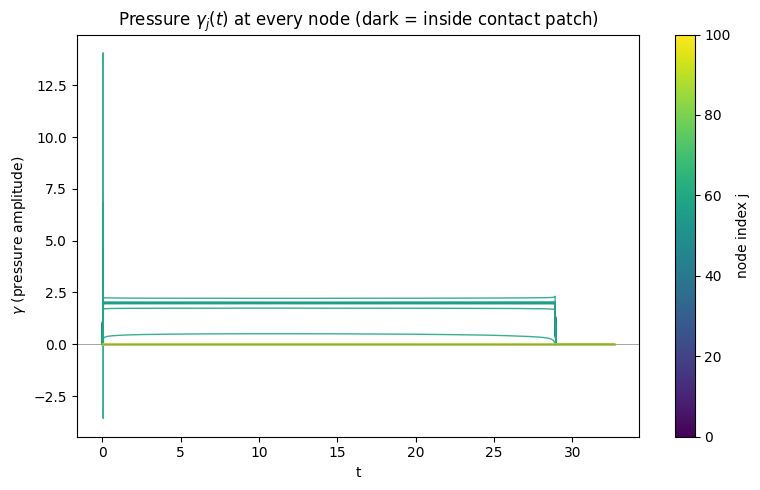

saved pressure_amplitudes.png


In [108]:
gamma_hist = np.array([unflatten(x, N)[2] for x in all_xs_arr])   # shape (num_steps, N)

fig2, ax2 = plt.subplots(figsize=(8, 5))
cmap = plt.cm.viridis
for node in range(N):
    color = cmap(node / (N - 1))
    ax2.plot(all_ts_arr, gamma_hist[:, node], color=color, lw=1,
              alpha=0.9 if node <= 2 * I else 0.3)  # contact-zone nodes emphasized

ax2.axhline(0, color="gray", lw=0.5)
ax2.set_xlabel("t")
ax2.set_ylabel(r"$\gamma$ (pressure amplitude)")
ax2.set_title(r"Pressure $\gamma_j(t)$ at every node (dark = inside contact patch)")

sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(0, N - 1))
sm.set_array([])
cbar = fig2.colorbar(sm, ax=ax2)
cbar.set_label("node index j")

fig2.tight_layout()
#fig2.savefig("pressure_amplitudes.png", dpi=150)
plt.show()
print("saved pressure_amplitudes.png")

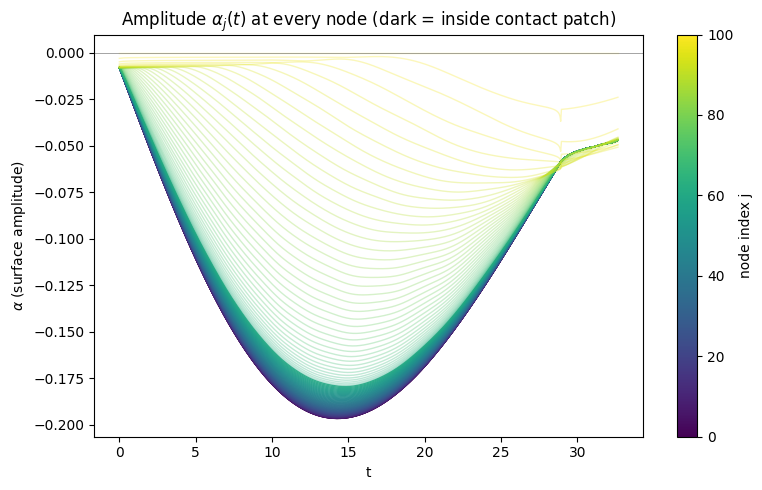

saved pressure_amplitudes.png


In [109]:
alpha_hist = np.array([unflatten(x, N)[0] for x in all_xs_arr])   # shape (num_steps, N)

fig2, ax2 = plt.subplots(figsize=(8, 5))
cmap = plt.cm.viridis
for node in range(N):
    color = cmap(node / (N - 1))
    ax2.plot(all_ts_arr, alpha_hist[:, node], color=color, lw=1,
              alpha=0.9 if node <= 2 * I else 0.3)  # contact-zone nodes emphasized

ax2.axhline(0, color="gray", lw=0.5)
ax2.set_xlabel("t")
ax2.set_ylabel(r"$\alpha$ (surface amplitude)")
ax2.set_title(r"Amplitude $\alpha_j(t)$ at every node (dark = inside contact patch)")

sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(0, N - 1))
sm.set_array([])
cbar = fig2.colorbar(sm, ax=ax2)
cbar.set_label("node index j")

fig2.tight_layout()
#fig2.savefig("pressure_amplitudes.png", dpi=150)
plt.show()
print("saved pressure_amplitudes.png")

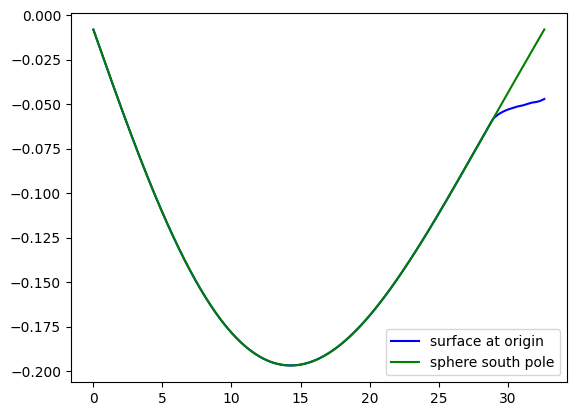

In [110]:
alpha_hist = np.array([unflatten(x, N)[0] for x in all_xs_arr]) 
h_hist = np.array([unflatten(x, N)[-3] for x in all_xs_arr]) 
plt.plot(all_ts_arr, alpha_hist[:, 0], color="blue", label="surface at origin")
plt.plot(all_ts_arr, h_hist-1, color="green", label="sphere south pole")
plt.legend()
plt.show()

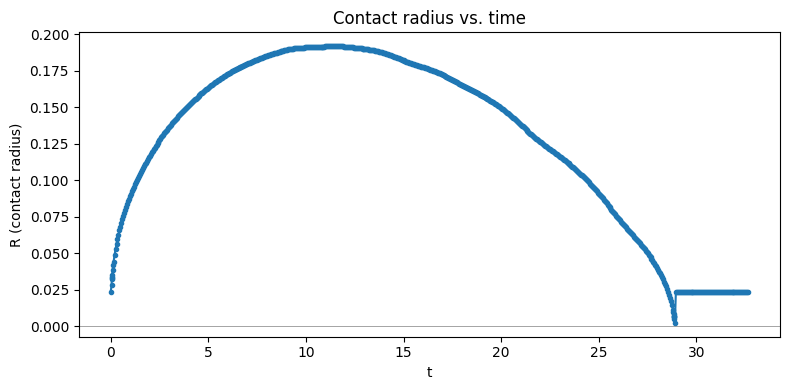

saved R_vs_time.png


In [111]:
R_hist = np.array([unflatten(x, N)[5] for x in all_xs])   # unflatten returns (a,b,g,h,v,R)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(all_ts, R_hist, "o-", color="tab:blue", ms=3, lw=1.5)
ax.set_xlabel("t")
ax.set_ylabel("R (contact radius)")
ax.set_title("Contact radius vs. time")
ax.axhline(0, color="gray", lw=0.5)
fig.tight_layout()
fig.savefig("R_vs_time.png", dpi=150)
plt.show()
print("saved R_vs_time.png")

In [112]:
SUBFRAMES = 4      # linear interpolation between saved steps, for smoother playback
E = 50
I = 30
N = 2 * E + 1
SPHERE_RADIUS = 1  # radius in your non-dimensional units (Ra if you didn't scale by it)

# ---------- build frames ----------
frames = []
for k in range(len(all_xs_arr) - 1):
    a0, b0, g0, h0, v0, R0 = unflatten(all_xs_arr[k], N)
    a1, b1, g1, h1, v1, R1 = unflatten(all_xs_arr[k + 1], N)
    t0, t1 = all_ts_arr[k], all_ts_arr[k + 1]
    for s in range(SUBFRAMES):
        f = s / SUBFRAMES
        a = (1 - f) * a0 + f * a1
        h = (1 - f) * h0 + f * h1
        R = (1 - f) * R0 + f * R1
        t = (1 - f) * t0 + f * t1
        X, _, _ = mesh_from_R(R, I, E, L, non_contact_X)      # interpolated R, not R0
        frames.append((t, X, a, h, R))

a_last, _, _, h_last, _, R_last = unflatten(all_xs_arr[-1], N)
X_last, _, _ = mesh_from_R(R_last, I, E, L, non_contact_X)
frames.append((all_ts_arr[-1], X_last, a_last, h_last, R_last))

print("mesh extends to:", frames[0][1][-1], " L =", L)   # sanity check: should match

# ---------- axis limits ----------
x_max = max(f[1][-1] for f in frames)                     # = L if the mesh is right
all_alpha = np.concatenate([f[2] for f in frames])
all_h = np.array([f[3] for f in frames])
y_min = min(all_alpha.min(), (all_h - SPHERE_RADIUS).min()) - 0.05
y_max = max(all_alpha.max(), (all_h + SPHERE_RADIUS).max()) + 0.05

# figure shape follows the data so equal aspect doesn't squash it
width = 12
height = np.clip(width * (y_max - y_min) / (2 * x_max), 3, 10)
fig, ax = plt.subplots(figsize=(width, height))

ax.set_xlim(-x_max, x_max)
ax.set_ylim(y_min, y_max)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("r"); ax.set_ylabel("z")
ax.axhline(0, color="gray", lw=0.5)

# ---------- artists ----------
membrane_line, = ax.plot([], [], "b-", lw=2, label=r"membrane $\eta(r)$")
sphere_patch = plt.Circle((0, 0), SPHERE_RADIUS, facecolor="grey",
                            edgecolor="black", lw=1.5, alpha=0.85, zorder=5)
ax.add_patch(sphere_patch)
contact_marker, = ax.plot([], [], "ko", ms=4, zorder=6)
title_txt = ax.set_title("")
ax.legend(loc="upper right")

def update(frame):
    t, X, a, h, R = frame
    r_full = np.concatenate([-X[::-1], X])
    a_full = np.concatenate([a[::-1], a])
    membrane_line.set_data(r_full, a_full)
    sphere_patch.center = (0, h)
    contact_marker.set_data([-R, R], [np.interp(R, X, a)] * 2)
    title_txt.set_text(f"t = {t:.4f}   h = {h:.4f}   R = {R:.4f}")
    return membrane_line, sphere_patch, contact_marker, title_txt

ani = animation.FuncAnimation(fig, update, frames=frames, blit=False, interval=1000 / 20)
ani.save(f'impact_simulation_elements={E}.mp4', writer="ffmpeg", fps=200, dpi=120)
plt.close(fig)
print(f"saved impact_simulation_elements={E}.mp4")

mesh extends to: 22.058823529698948  L = 22.05882352941176
saved impact_simulation_elements=50.mp4
